In [1]:
print("Hola Marcelo")

Hola Marcelo


In [2]:
import pandas as pd

print(pd.__version__)

2.3.3


In [3]:
import pandas as pd

races = pd.read_csv("races.csv")
results = pd.read_csv("results.csv")
drivers = pd.read_csv("drivers.csv")

print("Races:", races.shape)
print("Results:", results.shape)
print("Drivers:", drivers.shape)

Races: (1125, 18)
Results: (26759, 18)
Drivers: (861, 9)


In [4]:
import pandas as pd
import sqlite3

# Crear la base de datos
conn = sqlite3.connect("formula1.db")

# Lista de tablas
archivos = [
    "circuits",
    "constructor_results",
    "constructor_standings",
    "constructors",
    "driver_standings",
    "drivers",
    "lap_times",
    "pit_stops",
    "qualifying",
    "races",
    "results",
    "seasons",
    "sprint_results",
    "status"
]

# Cargar cada CSV a SQLite
for tabla in archivos:
    df = pd.read_csv(f"{tabla}.csv")
    df.to_sql(tabla, conn, if_exists="replace", index=False)

print("Base de datos creada correctamente")

conn.close()

Base de datos creada correctamente


Estoy probando los comentarios con Markdown

In [5]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("formula1.db")

df = pd.read_sql(
    "SELECT * FROM drivers LIMIT 10",
    conn
)

df

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,\N,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
6,7,bourdais,\N,BOU,Sébastien,Bourdais,1979-02-28,French,http://en.wikipedia.org/wiki/S%C3%A9bastien_Bo...
7,8,raikkonen,7,RAI,Kimi,Räikkönen,1979-10-17,Finnish,http://en.wikipedia.org/wiki/Kimi_R%C3%A4ikk%C...
8,9,kubica,88,KUB,Robert,Kubica,1984-12-07,Polish,http://en.wikipedia.org/wiki/Robert_Kubica
9,10,glock,\N,GLO,Timo,Glock,1982-03-18,German,http://en.wikipedia.org/wiki/Timo_Glock


Verificación de la base de datos SQLite
Se verificó la creación correcta de la base de datos SQLite denominada formula1.db mediante consultas al catálogo interno sqlite_master. Asimismo, se realizaron consultas SQL para recuperar registros de las tablas almacenadas.

Visualización 1: Número de carreras por temporada
Se analiza la evolución del número de carreras disputadas en cada temporada de Fórmula 1.

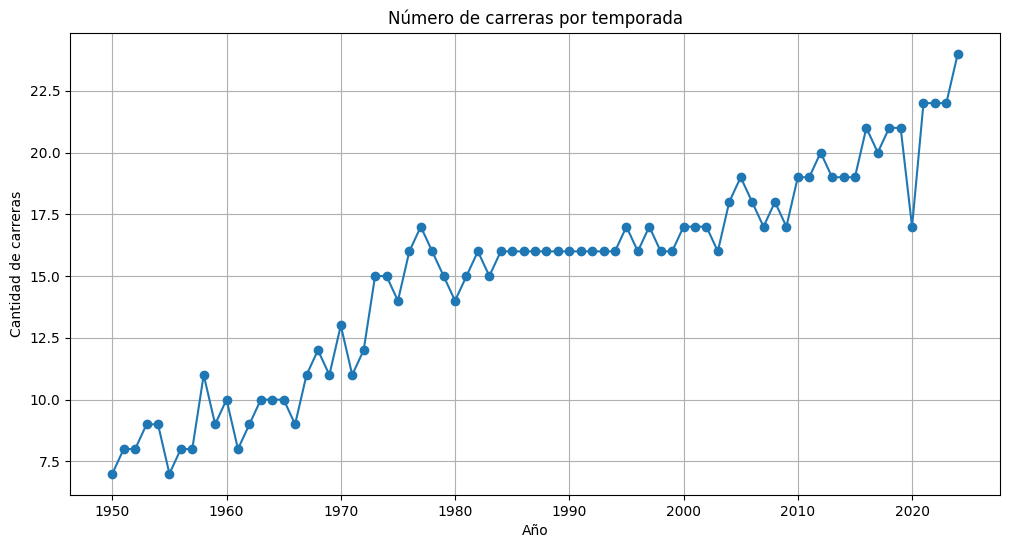

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

races = pd.read_csv("races.csv")

carreras_por_anio = races.groupby("year").size()

plt.figure(figsize=(12,6))
plt.plot(carreras_por_anio.index,
         carreras_por_anio.values,
         marker='o')

plt.title("Número de carreras por temporada")
plt.xlabel("Año")
plt.ylabel("Cantidad de carreras")
plt.grid(True)

plt.show()

Visualización 2: Pilotos con mayor número de participaciones

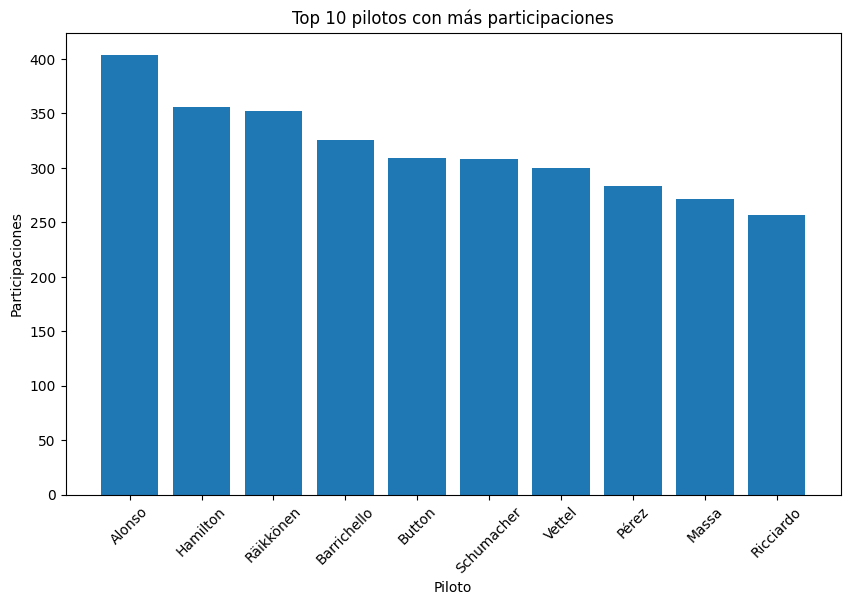

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("results.csv")
drivers = pd.read_csv("drivers.csv")

participaciones = results.groupby("driverId").size()

top10 = participaciones.sort_values(
    ascending=False
).head(10)

top10_df = pd.DataFrame(top10).reset_index()

top10_df = top10_df.merge(
    drivers[['driverId','surname']],
    on='driverId'
)

plt.figure(figsize=(10,6))

plt.bar(top10_df['surname'],
        top10_df[0])

plt.title("Top 10 pilotos con más participaciones")
plt.xlabel("Piloto")
plt.ylabel("Participaciones")

plt.xticks(rotation=45)

plt.show()

Visualización 3: Distribución de posiciones finales

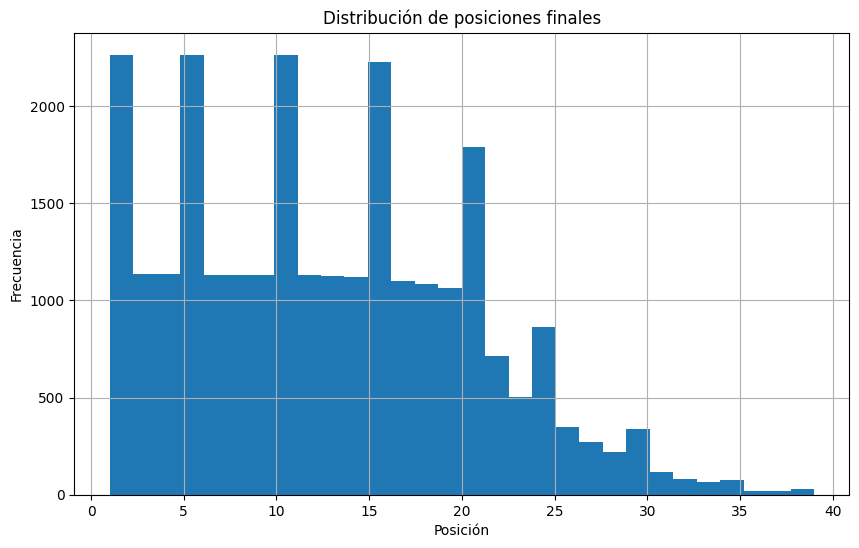

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("results.csv")

plt.figure(figsize=(10,6))

results["positionOrder"].hist(
    bins=30
)

plt.title("Distribución de posiciones finales")
plt.xlabel("Posición")
plt.ylabel("Frecuencia")

plt.show()

Visualización 5: Datos consultados desde SQLite

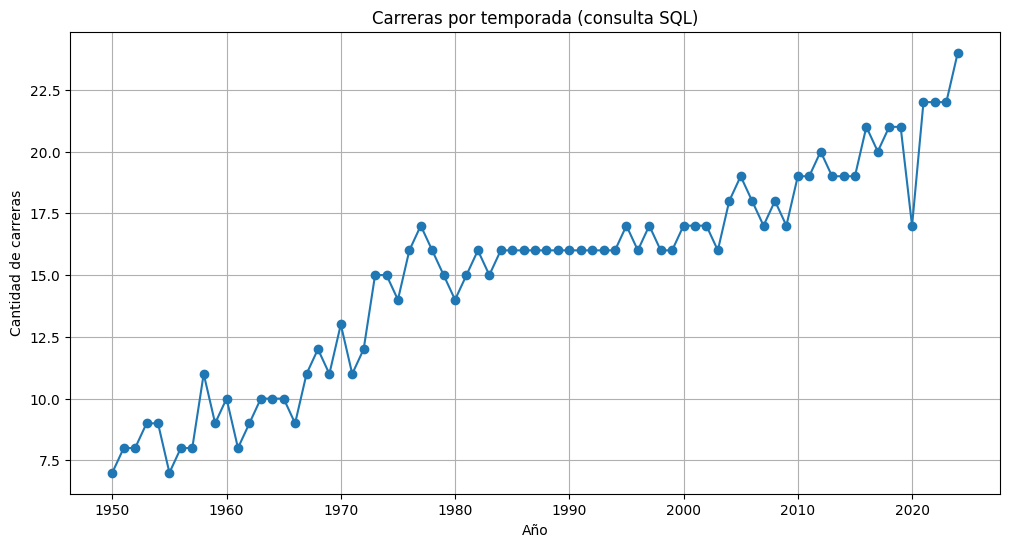

In [9]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("formula1.db")

consulta = """
SELECT year,
       COUNT(*) as carreras
FROM races
GROUP BY year
ORDER BY year
"""

df = pd.read_sql(consulta, conn)

conn.close()

plt.figure(figsize=(12,6))

plt.plot(
    df["year"],
    df["carreras"],
    marker='o'
)

plt.title("Carreras por temporada (consulta SQL)")
plt.xlabel("Año")
plt.ylabel("Cantidad de carreras")

plt.grid(True)

plt.show()